# Finance
*Pricing options by simulation, and their Greeks*

A European option pays off on the price of an asset at one date. Its fair price is the discounted expected payoff, and a Monte Carlo estimate of it is the average over simulated price paths. This page prices calls, puts and digitals over a grid of strikes and maturities with one lane per path, takes the Greeks by differentiating the simulation, and checks every number against Black-Scholes. Then it prices an Asian option, which has no closed form.

**Time:** ~5 min &middot; **Runs on:** CPU (same code on GPU) &middot;
**You need:** hawk, eagle, NumPy and matplotlib; read first: [hawk in your domain](../vocabulary)

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "hawk"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/hawk/{ref}/{rel}", root / rel)
    (root / "docs/content/vocabulary").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/vocabulary")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "_shared"))
from nb_helpers import gpu_available, on_device, plot_style, show, to_numpy, xp
plot_style()

## The market, once

The asset follows geometric Brownian motion under the risk-neutral measure: `S(T) = S0 exp((r - vol^2 / 2) T + vol sqrt(T) Z)`, with `Z` a standard normal draw, a risk-free rate `r` and a constant volatility. The model leaves out jumps, stochastic volatility, dividends and early exercise. For those, and for production risk systems, reach for a quantitative-finance library.

- Today's price is `S0 = 100`, the rate 3% a year and the volatility 20% a year. Prices are in the currency of `S0`; times are in years.
- A **call** pays `max(S(T) - K, 0)`, a **put** `max(K - S(T), 0)` and a **digital** call 1 if `S(T) > K`. Each is discounted by `exp(-r T)`.
- The **Greeks** are derivatives of the price: **delta** with respect to `S0`, **vega** with respect to the volatility and **rho** with respect to the rate.

Declare the market's words as a `KernelKind` once: the path number, the strike and maturity of the option the lane prices, and the three market inputs. The inputs are `Param`s because they are the variables the Greeks differentiate.

In [3]:
import math
import numpy as np
import eagle
import hawk
import hawk.math as m
from hawk import Index, Mutable, Param, Scalar, Vector
from hawk.ext import DATA_ONLY, KernelKind

SPOT, RATE, VOL = 100.0, 0.03, 0.20


class Market(KernelKind, slug="market"):
    seed: Index[np.int64]       # the path number: with a draw counter, it fixes every random number
    strike: Scalar      # strike of this option (one per lane, so a sweep is one call)
    maturity: Scalar    # time to expiry (years)
    spot: Param         # today's price of the underlying
    vol: Param          # volatility (per square-root year)
    rate: Param         # risk-free rate (per year)
    guard = DATA_ONLY

Market

__main__.Market

## One path

The kernel draws one normal number from hawk's counter-based generator, `hawk.math.random`: a draw is a pure function of the seed (the path number) and a counter. So a path is the same on every run, on a CPU or a GPU, and the same path prices every option, which also shares the random numbers between strikes. It builds `S(T)` and writes the three payoffs, and a fourth output, `digital_lr`: the likelihood-ratio estimate of the digital's delta, which the Greeks section uses.

In [4]:
@Market
def european(seed, strike, maturity, spot, vol, rate,
             call: Mutable[Scalar], put: Mutable[Scalar], digital: Mutable[Scalar], digital_lr: Mutable[Scalar]):
    z = m.random.normal(seed, 0)                                                   # the one random number of the path
    s_end = spot * m.exp((rate - 0.5 * vol * vol) * maturity + vol * m.sqrt(maturity) * z)
    disc = m.exp(-rate * maturity)
    in_the_money = s_end > strike
    call = disc * m.where(in_the_money, s_end - strike, 0.0)
    put = disc * m.where(in_the_money, 0.0, strike - s_end)
    digital = disc * m.where(in_the_money, 1.0, 0.0)
    digital_lr = digital * z / (spot * vol * m.sqrt(maturity))                    # the likelihood-ratio estimate of the digital's delta


european

<Kernel european slots=10>

## A sweep of options

Five strikes (80 to 120) and three maturities (0.5, 1 and 2 years): 15 options, 20 000 paths each, 300 000 lanes in one call. `eagle.deploy(european).run(...)` takes the planes by name and returns the payoffs by name; the price is the mean over an option's paths and its standard error is the spread of the payoffs over `sqrt(N)`.

In [5]:
STRIKES = np.array([80.0, 90.0, 100.0, 110.0, 120.0])
MATURITIES = np.array([0.5, 1.0, 2.0])
N = 20_000                                                  # paths per option
options = [(k, t) for t in MATURITIES for k in STRIKES]    # 15 options
NO = len(options)
opt_strike = np.repeat([k for k, _ in options], N)
opt_maturity = np.repeat([t for _, t in options], N)
opt_seed = np.tile(np.arange(N), NO)                        # the same paths price every option

pricer = eagle.deploy(european)
out = pricer.run(seed=opt_seed, strike=opt_strike, maturity=opt_maturity, spot=SPOT, vol=VOL, rate=RATE, returns="numpy")


def per_option(plane):
    return plane.reshape(NO, N)


def mean_and_error(plane):
    x = per_option(plane)
    return x.mean(axis=1), x.std(axis=1, ddof=1) / np.sqrt(N)


price, price_se = mean_and_error(out["call"])
print(f"{NO} options x {N} paths = {NO * N} lanes; at the money, 1 year: call {price[7]:.3f} +- {price_se[7]:.3f}")

15 options x 20000 paths = 300000 lanes; at the money, 1 year: call 9.438 +- 0.099


## Check it against Black-Scholes

Black-Scholes has a closed form for the call, the put, the digital and all three Greeks. Every Monte Carlo price must lie within four of its own standard errors of it. Put-call parity is a second, independent check: `call - put = exp(-r T) S(T) - K exp(-r T)` holds path by path, so its mean must be `S0 - K exp(-r T)`.

In [6]:
def Phi(x): return 0.5 * (1.0 + np.vectorize(math.erf)(np.asarray(x) / math.sqrt(2.0)))
def phi(x): return np.exp(-0.5 * np.asarray(x) ** 2) / math.sqrt(2 * math.pi)


def black_scholes(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    disc = np.exp(-r * T)
    return dict(call=S * Phi(d1) - K * disc * Phi(d2), put=K * disc * Phi(-d2) - S * Phi(-d1), digital=disc * Phi(d2),
                delta=Phi(d1), vega=S * phi(d1) * np.sqrt(T), rho=K * T * disc * Phi(d2),
                digital_delta=disc * phi(d2) / (sigma * S * np.sqrt(T)))


K_all, T_all = np.array([k for k, _ in options]), np.array([t for _, t in options])
bs = black_scholes(SPOT, K_all, T_all, RATE, VOL)

Z_MAX = 4.0
for name in ("call", "put", "digital"):
    mean, se = mean_and_error(out[name])
    z = (mean - bs[name]) / se
    assert np.abs(z).max() < Z_MAX, (name, z)
    print(f"{name:>8}: {NO} options, worst deviation from Black-Scholes {np.abs(z).max():.1f} standard errors < {Z_MAX:g}")

# put-call parity, path by path: call - put = e^{-rT} (S_T - K), whose mean is S0 - K e^{-rT}
diff = per_option(out["call"]) - per_option(out["put"])
z_parity = (diff.mean(axis=1) - (SPOT - K_all * np.exp(-RATE * T_all))) / (diff.std(axis=1, ddof=1) / np.sqrt(N))
assert np.abs(z_parity).max() < Z_MAX, z_parity
print(f"put-call parity: worst deviation {np.abs(z_parity).max():.1f} standard errors < {Z_MAX:g}")

    call: 15 options, worst deviation from Black-Scholes 1.7 standard errors < 4
     put: 15 options, worst deviation from Black-Scholes 2.4 standard errors < 4
 digital: 15 options, worst deviation from Black-Scholes 1.9 standard errors < 4
put-call parity: worst deviation 1.6 standard errors < 4


## How the error falls with the number of paths

Monte Carlo is first order in `1 / sqrt(N)`. To measure it, run many independent batches of `N` paths at the money for one year, and compare the rms error of the batch prices to the exact price with one standard error. The ratio should stay near one for every `N`, and the fitted slope on log axes should be minus one half.

In [7]:
total = 3_200_000
big = pricer.run(seed=np.arange(total) + 10**8, strike=np.full(total, 100.0), maturity=np.full(total, 1.0), spot=SPOT, vol=VOL, rate=RATE, returns="numpy")
exact = black_scholes(SPOT, 100.0, 1.0, RATE, VOL)["call"]
sd = np.std(big["call"], ddof=1)                             # one payoff's spread
ratios, rms_all, sizes = [], [], (500, 5_000, 50_000)
for n_paths in sizes:
    estimates = big["call"].reshape(-1, n_paths).mean(axis=1)
    rms = np.sqrt(np.mean((estimates - exact) ** 2))
    rms_all.append(rms)
    ratios.append(rms / (sd / np.sqrt(n_paths)))
    print(f"N = {n_paths:>7}: {len(estimates):>5} batches, rms error {rms:.3f}, sd/sqrt(N) = {sd / np.sqrt(n_paths):.3f}, ratio {ratios[-1]:.2f}")
assert all(0.7 < r < 1.3 for r in ratios), ratios
order = -np.polyfit(np.log(sizes), np.log(rms_all), 1)[0]
print(f"fitted order: the rms error falls as N^-{order:.2f} (expected 0.5)")
assert abs(order - 0.5) < 0.1, order

N =     500:  6400 batches, rms error 0.632, sd/sqrt(N) = 0.631, ratio 1.00
N =    5000:   640 batches, rms error 0.198, sd/sqrt(N) = 0.200, ratio 0.99
N =   50000:    64 batches, rms error 0.065, sd/sqrt(N) = 0.063, ratio 1.03
fitted order: the rms error falls as N^-0.49 (expected 0.5)


## The Greeks, by differentiating the simulation

`hawk.diff.jvp(european, wrt=("spot", "vol", "rate"))` derives the forward-mode kernel, which pushes a unit change of one input through the path and its payoff. This is the **pathwise** method: differentiate each path, then average. `eagle.deploy` takes the kernel and its derivative together and runs either by name; one launch per input gives delta, vega and rho for all 300 000 lanes.

**Why this is valid for a call.** For a fixed random draw the call payoff is a continuous function of `S0`, `vol` and `r`. It has a kink at the strike but no jump, so it is differentiable except on a set of paths of probability zero, and the derivative of the average is the average of the derivatives. The kernel's `where` takes the derivative of the branch the path is on, which is exactly this.

**Where it fails.** A digital payoff jumps at the strike. Each path's derivative is zero, but the average moves, because paths cross the strike as `S0` moves; the contribution at the jump is missing. The pathwise delta of a digital is therefore wrong, and the page shows how. The remedy is the likelihood-ratio method, which moves the derivative from the payoff onto the density of the draw: the digital's delta is the average of `payoff * z / (S0 vol sqrt(T))`. The kernel's fourth output computes it in one line, and the page checks it against Black-Scholes. (The other usual remedy is a smoothed payoff; [Nuclear](14_nuclear) uses the likelihood ratio for a tally that jumps.)

In [8]:
from hawk import Kernel
from hawk.diff import jvp

european_jvp = Kernel("european_jvp", jvp(european, wrt=("spot", "vol", "rate")))
pricer, forward = eagle.deploy([european, european_jvp])
lanes = dict(seed=opt_seed, strike=opt_strike, maturity=opt_maturity, spot=SPOT, vol=VOL, rate=RATE, returns="numpy")
direction = {"spot": dict(dot_spot=1.0, dot_vol=0.0, dot_rate=0.0), "vol": dict(dot_spot=0.0, dot_vol=1.0, dot_rate=0.0),
             "rate": dict(dot_spot=0.0, dot_vol=0.0, dot_rate=1.0)}
greeks = {g: forward.run(**lanes, **d) for g, d in direction.items()}          # one jvp launch per input
delta, delta_se = mean_and_error(greeks["spot"]["dot_call"])
vega, vega_se = mean_and_error(greeks["vol"]["dot_call"])
rho, rho_se = mean_and_error(greeks["rate"]["dot_call"])
for name, mean, se in (("delta", delta, delta_se), ("vega", vega, vega_se), ("rho", rho, rho_se)):
    z = (mean - bs[name]) / se
    assert np.abs(z).max() < Z_MAX, (name, z)
    print(f"{name:>5}: {NO} options, worst deviation from the Black-Scholes value {np.abs(z).max():.1f} standard errors < {Z_MAX:g}")

put_delta, put_delta_se = mean_and_error(greeks["spot"]["dot_put"])
parity = per_option(greeks["spot"]["dot_call"]) - per_option(greeks["spot"]["dot_put"])     # d(call - put) / d spot = 1 on average
z_parity = (parity.mean(axis=1) - 1.0) / (parity.std(axis=1, ddof=1) / np.sqrt(N))
assert np.abs(z_parity).max() < Z_MAX and np.abs(put_delta - (bs["delta"] - 1)).max() < Z_MAX * put_delta_se.max()
print(f"call delta - put delta = 1: worst deviation {np.abs(z_parity).max():.1f} standard errors")

d_digital = greeks["spot"]["dot_digital"]
print(f"digital: the pathwise delta is {np.abs(d_digital).max():.1f} on every path; Black-Scholes says {bs['digital_delta'][7]:.4f} at the money, 1 year")
assert (d_digital == 0.0).all() and (bs["digital_delta"] > 0.005).all()

lr, lr_se = mean_and_error(pricer.run(**lanes)["digital_lr"])
z_lr = (lr - bs["digital_delta"]) / lr_se
assert np.abs(z_lr).max() < Z_MAX, z_lr
print(f"digital, likelihood ratio: {lr[7]:.5f} +- {lr_se[7]:.5f} against {bs['digital_delta'][7]:.5f} at the money, 1 year; worst deviation over {NO} options {np.abs(z_lr).max():.1f} standard errors < {Z_MAX:g}")

delta: 15 options, worst deviation from the Black-Scholes value 1.7 standard errors < 4
 vega: 15 options, worst deviation from the Black-Scholes value 1.7 standard errors < 4
  rho: 15 options, worst deviation from the Black-Scholes value 1.9 standard errors < 4
call delta - put delta = 1: worst deviation 1.6 standard errors
digital: the pathwise delta is 0.0 on every path; Black-Scholes says 0.0193 at the money, 1 year
digital, likelihood ratio: 0.01939 +- 0.00020 against 0.01933 at the money, 1 year; worst deviation over 15 options 1.8 standard errors < 4


## A path-dependent option with no closed form

An **arithmetic Asian call** pays on the average of the price at 12 monthly fixings: `max(average - K, 0)`. There is no closed form for it. The loop over the fixings is the path, written once in the kernel. The same kernel also prices the **geometric** Asian call, whose average is a product and whose price has a closed form (Kemna and Vorst). That gives two checks:

- the simulated geometric price must match its closed form, which tests the path;
- the geometric payoff is a **control variate** for the arithmetic one: the two are almost perfectly correlated, so subtracting the geometric error removes most of the noise. The control-variate price has a far smaller standard error, and an independent plain run with four times the paths must agree with it, to the plain run's own standard error (the control variate is much tighter than that check can see).

The Greeks come from the same pathwise `jvp`. Their check is a central finite difference of the price with **common random numbers**: the same paths at `S0 +- h` and `vol +- h`, so the difference is smooth and the comparison sharp. The geometric Asian delta has a closed form too, `exp(-rT) exp(mu + var / 2) Phi(d1) / S0`, and the pathwise delta must match it. The kernel also returns the twelve fixings of each path, for the picture.

In [9]:
STEPS = 12                                                 # monthly fixings for a one-year option


def no_fixings():
    return m.vec(*[0.0] * STEPS)


@Market
def asian(seed, strike, maturity, spot, vol, rate, arithmetic: Mutable[Scalar], geometric: Mutable[Scalar],
          fixings: Mutable[Vector[STEPS]]):
    dt = maturity / STEPS
    drift = (rate - 0.5 * vol * vol) * dt
    spread = vol * m.sqrt(dt)
    s = spot
    total = 0.0
    log_total = 0.0
    path = no_fixings()
    for i in range(STEPS):
        s = s * m.exp(drift + spread * m.random.normal(seed, i))
        total = total + s
        log_total = log_total + m.log(s)
        path[i] = s
    disc = m.exp(-rate * maturity)
    arithmetic = disc * m.where(total / STEPS > strike, total / STEPS - strike, 0.0)
    geometric = disc * m.where(m.exp(log_total / STEPS) > strike, m.exp(log_total / STEPS) - strike, 0.0)
    fixings = path


asian_jvp = Kernel("asian_jvp", jvp(asian, wrt=("spot", "vol")))
asian_pricer, asian_forward = eagle.deploy([asian, asian_jvp])
NA = 40_000
a_strike = np.repeat(STRIKES, NA)


def asian_lanes(offset=0, paths=NA, spot=SPOT, vol=VOL):
    return dict(seed=np.tile(np.arange(paths), len(STRIKES)) + offset, strike=np.repeat(STRIKES, paths), maturity=np.ones(paths * len(STRIKES)),
                spot=spot, vol=vol, rate=RATE, returns="numpy")


def asian_mean(plane, paths=NA):
    x = plane.reshape(len(STRIKES), paths)
    return x.mean(axis=1), x.std(axis=1, ddof=1) / np.sqrt(paths)


run = asian_pricer.run(**asian_lanes())
arith, arith_se = asian_mean(run["arithmetic"])
geo, geo_se = asian_mean(run["geometric"])

# the geometric average has a closed form (Kemna-Vorst): its log is Gaussian with the mean and variance below
dt = 1.0 / STEPS
mu_g = np.log(SPOT) + (RATE - 0.5 * VOL**2) * dt * (STEPS + 1) / 2
var_g = VOL**2 * dt * (STEPS + 1) * (2 * STEPS + 1) / (6 * STEPS)
d1 = (mu_g + var_g - np.log(STRIKES)) / np.sqrt(var_g)
geo_exact = np.exp(-RATE) * (np.exp(mu_g + var_g / 2) * Phi(d1) - STRIKES * Phi(d1 - np.sqrt(var_g)))
z_geo = (geo - geo_exact) / geo_se
assert np.abs(z_geo).max() < Z_MAX, z_geo
print(f"geometric Asian against its closed form: worst deviation {np.abs(z_geo).max():.1f} standard errors < {Z_MAX:g}")

# the arithmetic Asian has none: use the geometric one as a control variate, then check the plain estimate of an independent run against it
A, G = run["arithmetic"].reshape(len(STRIKES), NA), run["geometric"].reshape(len(STRIKES), NA)
beta = np.array([np.cov(a, g)[0, 1] / np.var(g, ddof=1) for a, g in zip(A, G)])
controlled = A - beta[:, None] * (G - geo_exact[:, None])
cv, cv_se = controlled.mean(axis=1), controlled.std(axis=1, ddof=1) / np.sqrt(NA)
independent = asian_pricer.run(**asian_lanes(offset=10**7, paths=4 * NA))
plain, plain_se = asian_mean(independent["arithmetic"], paths=4 * NA)
z_cv = (plain - cv) / np.hypot(plain_se, cv_se)
assert np.abs(z_cv).max() < Z_MAX, z_cv
print(f"arithmetic Asian: control-variate price {cv.round(3)}, standard error {cv_se.max():.4f} against {arith_se.max():.4f} for the plain mean")
print(f"an independent plain run agrees with the control-variate price: worst deviation {np.abs(z_cv).max():.1f} standard errors < {Z_MAX:g}")

# Greeks: pathwise jvp against central differences with common random numbers (the same paths at spot +- h and vol +- h)
delta_a, vega_a = (asian_mean(asian_forward.run(**asian_lanes(), **d)["dot_arithmetic"])[0]
                   for d in (dict(dot_spot=1.0, dot_vol=0.0), dict(dot_spot=0.0, dot_vol=1.0)))
h = 1e-3
fd_delta = (asian_mean(asian_pricer.run(**asian_lanes(spot=SPOT + h))["arithmetic"])[0] - asian_mean(asian_pricer.run(**asian_lanes(spot=SPOT - h))["arithmetic"])[0]) / (2 * h)
fd_vega = (asian_mean(asian_pricer.run(**asian_lanes(vol=VOL + h * 1e-2))["arithmetic"])[0] - asian_mean(asian_pricer.run(**asian_lanes(vol=VOL - h * 1e-2))["arithmetic"])[0]) / (2 * h * 1e-2)
TOL_FD = 5e-4
gap = max(np.abs(delta_a - fd_delta).max() / np.abs(fd_delta).max(), np.abs(vega_a - fd_vega).max() / np.abs(fd_vega).max())
assert gap < TOL_FD, gap
print(f"Asian delta and vega, pathwise against common-random-number differences: worst gap {gap:.1e} of the largest value < {TOL_FD:g}")
print("Asian delta by strike:", delta_a.round(3))

# the geometric Asian delta against its closed form: exp(-rT) exp(mu_g + var_g / 2) Phi(d1) / S0
geo_delta_exact = np.exp(-RATE) * np.exp(mu_g + var_g / 2) * Phi(d1) / SPOT
geo_delta, geo_delta_se = asian_mean(asian_forward.run(**asian_lanes(), dot_spot=1.0, dot_vol=0.0)["dot_geometric"])
z_geo_delta = (geo_delta - geo_delta_exact) / geo_delta_se
assert np.abs(z_geo_delta).max() < Z_MAX, z_geo_delta
print(f"geometric Asian delta, pathwise against its closed form: worst deviation {np.abs(z_geo_delta).max():.1f} standard errors < {Z_MAX:g}")

geometric Asian against its closed form: worst deviation 0.8 standard errors < 4


arithmetic Asian: control-variate price [21.096 12.243  5.633  2.01   0.565], standard error 0.0014 against 0.0601 for the plain mean
an independent plain run agrees with the control-variate price: worst deviation 0.8 standard errors < 4


Asian delta and vega, pathwise against common-random-number differences: worst gap 3.5e-05 of the largest value < 0.0005
Asian delta by strike: [0.965 0.841 0.566 0.278 0.097]
geometric Asian delta, pathwise against its closed form: worst deviation 1.3 standard errors < 4


## The picture

Left: 200 of the 12-fixing Asian paths for the strike-100 option, coloured by whether the average ends above the strike (a payoff) or not, with the strike as a dashed line; beside it, the histogram of the price at the year end over all 40 000 paths against the lognormal density the model implies. Right: delta against strike for one-year options. The pathwise call delta (blue dots with one standard error) follows the Black-Scholes line, the pathwise digital delta (orange squares) is zero for every strike, and the likelihood-ratio estimate (orange dots) sits on the exact digital delta (orange line, right-hand scale).


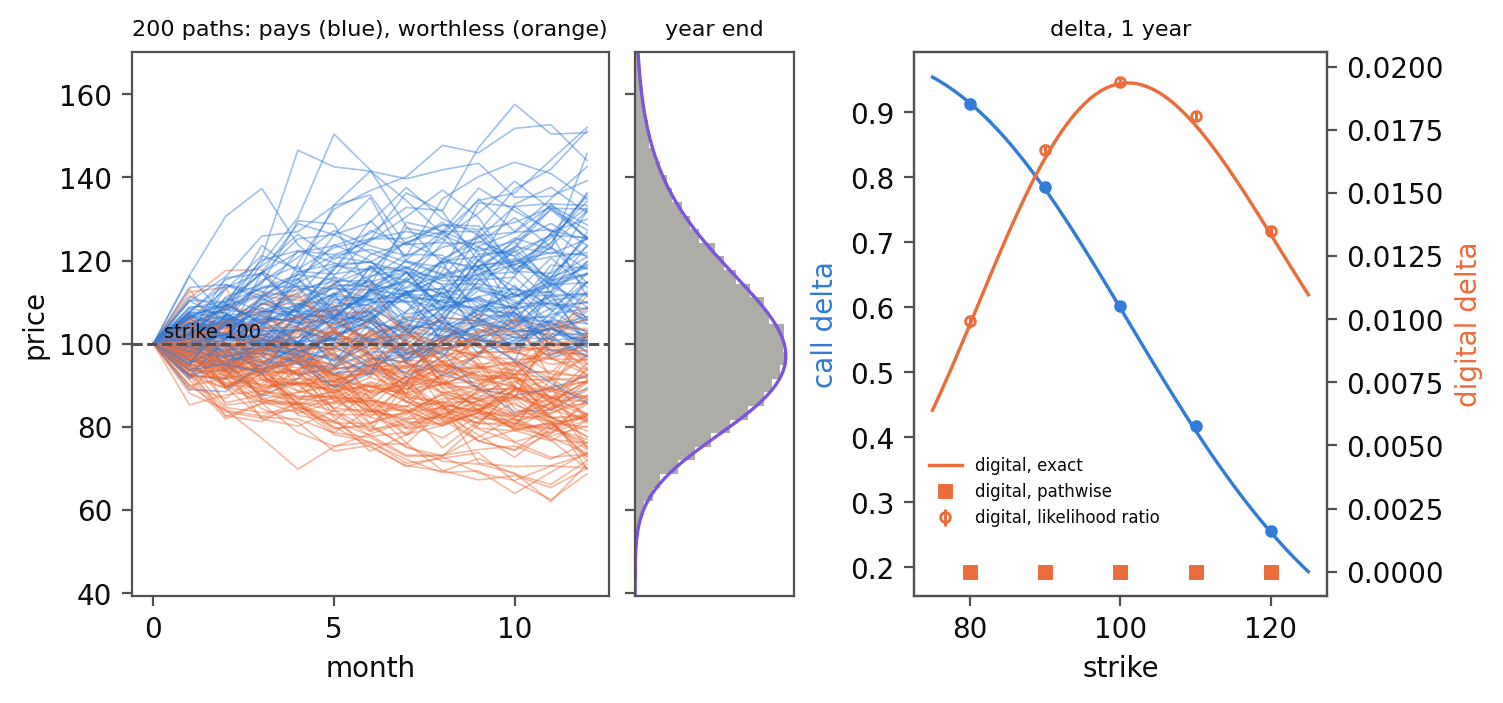
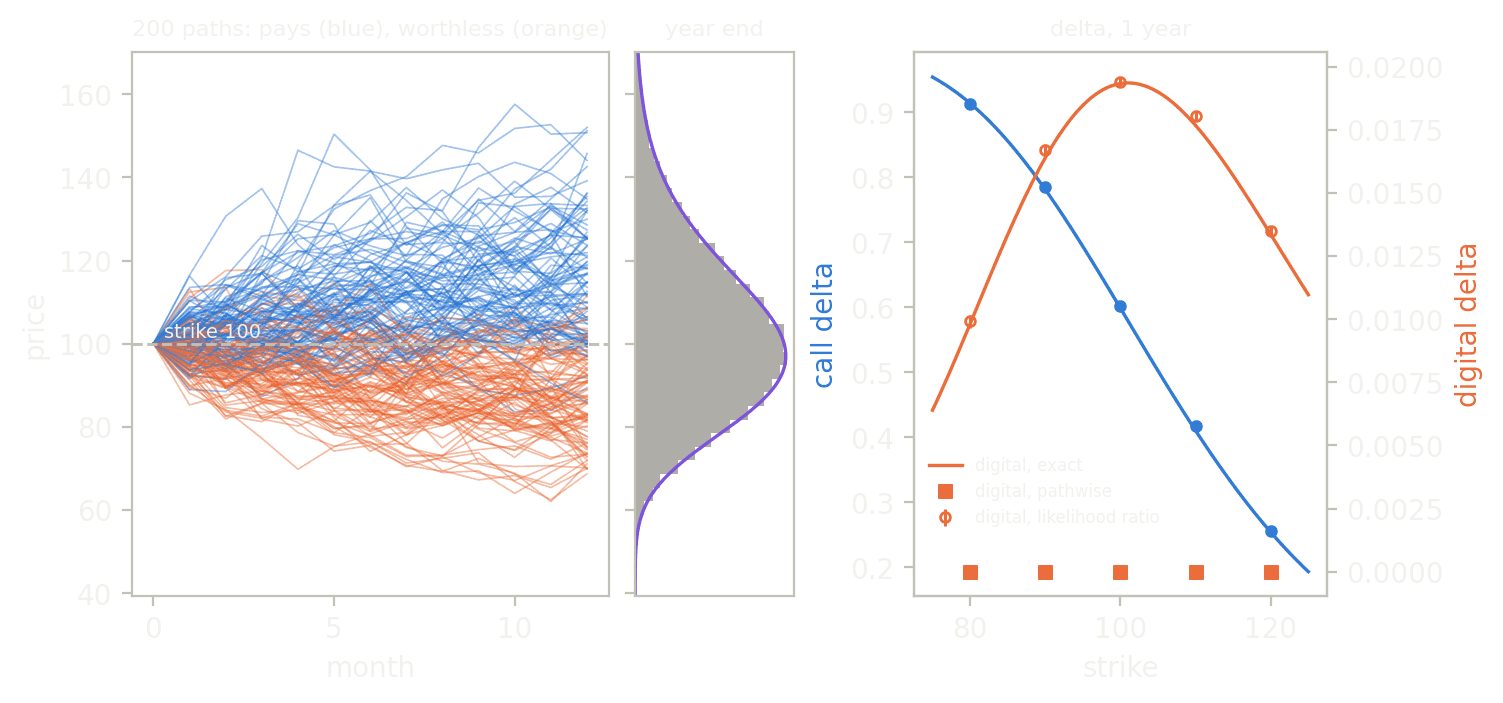

In [10]:
import matplotlib.pyplot as plt

# the fan: 200 paths of the strike-100 Asian option
strike_100 = 2 * NA
fan = run["fixings"][:, strike_100:strike_100 + NA]                  # (fixing, path)
pays = run["arithmetic"][strike_100:strike_100 + NA] > 0.0
months = np.arange(STEPS + 1)
end_prices = fan[-1]

one_year = slice(5, 10)
fig = plt.figure(figsize=(7.4, 3.4), constrained_layout=True)
spec = fig.add_gridspec(1, 3, width_ratios=[3.0, 1.0, 2.6])
paths_ax, hist_ax, delta_ax = fig.add_subplot(spec[0]), fig.add_subplot(spec[1]), fig.add_subplot(spec[2])
for j in range(200):
    paths_ax.plot(months, np.r_[SPOT, fan[:, j]], lw=0.6, color="#2a78d6" if pays[j] else "#eb6834", alpha=0.45)
paths_ax.axhline(100.0, ls="--", lw=1.0, color="#898781")
paths_ax.text(0.3, 101.5, "strike 100", fontsize=7)
paths_ax.set_xlabel("month"); paths_ax.set_ylabel("price"); paths_ax.set_title("200 paths: pays (blue), worthless (orange)", fontsize=8)
y_top = np.percentile(end_prices, 99.5)
grid_y = np.linspace(end_prices.min(), y_top, 200)
mu_T, sig_T = np.log(SPOT) + (RATE - 0.5 * VOL**2), VOL
density = np.exp(-0.5 * ((np.log(grid_y) - mu_T) / sig_T) ** 2) / (grid_y * sig_T * np.sqrt(2 * np.pi))
hist_ax.hist(end_prices[end_prices < y_top], bins=40, orientation="horizontal", density=True, color="#9a9992", alpha=0.8)
hist_ax.plot(density, grid_y, lw=1.2, color="#7d53dc")
hist_ax.set_xticks([]); hist_ax.set_title("year end", fontsize=8)
paths_ax.set_ylim(grid_y[0], y_top); hist_ax.set_ylim(grid_y[0], y_top)
hist_ax.set_yticklabels([])

fine = np.linspace(75, 125, 100)
ref = black_scholes(SPOT, fine, 1.0, RATE, VOL)
delta_ax.plot(fine, ref["delta"], lw=1.2, color="#2a78d6")
delta_ax.errorbar(STRIKES, delta[one_year], yerr=delta_se[one_year], fmt="o", ms=3.5, lw=1.0, color="#2a78d6")
delta_ax.set_xlabel("strike"); delta_ax.set_ylabel("call delta", color="#2a78d6"); delta_ax.set_title("delta, 1 year", fontsize=8)
dig_ax = delta_ax.twinx()
dig_ax.plot(fine, ref["digital_delta"], lw=1.2, color="#eb6834", label="digital, exact")
dig_ax.plot(STRIKES, np.zeros(5), "s", ms=4, color="#eb6834", label="digital, pathwise")
dig_ax.errorbar(STRIKES, lr[one_year], yerr=lr_se[one_year], fmt="o", ms=3.5, lw=1.0, color="#eb6834", mfc="none", label="digital, likelihood ratio")
dig_ax.set_ylabel("digital delta", color="#eb6834"); dig_ax.legend(frameon=False, fontsize=6, loc="lower left", bbox_to_anchor=(0.0, 0.1))
show(fig, f"Left: 200 price paths over 12 months starting at 100, fanning out around the dashed strike line at 100; {pays[:200].sum()} of the 200 end with an average above the strike and pay (blue), the rest expire worthless (orange). Beside them a histogram of the year-end price over {NA:,} paths follows the lognormal density curve. Right: delta against strike for one-year options. The pathwise call delta falls from {delta[5]:.2f} at strike 80 to {delta[9]:.2f} at strike 120 and sits on the Black-Scholes line; the exact digital delta is a bump of about {bs['digital_delta'][5:10].max():.3f} near the money, the pathwise digital estimate is zero everywhere, and the likelihood-ratio estimate follows the bump.")

## A bigger run, when a GPU is there

This cell runs only when a GPU is present; on a CPU runtime it prints that and does nothing. The same kernel and the same call run on device arrays: five million paths of the at-the-money one-year call, with its delta from the `jvp`. The delta must lie within four standard errors of Black-Scholes; one standard error is about 3e-4.

In [11]:
if gpu_available():
    paths = 5_000_000
    got = forward.run(seed=xp.arange(paths), strike=xp.full(paths, 100.0), maturity=xp.ones(paths), spot=SPOT, vol=VOL, rate=RATE,
                      dot_spot=1.0, dot_vol=0.0, dot_rate=0.0)
    assert on_device(got["dot_call"]), "the result is a device array: the kernel ran on the GPU"
    x = to_numpy(got["dot_call"])
    want = black_scholes(SPOT, 100.0, 1.0, RATE, VOL)["delta"]
    z = (x.mean() - want) / (x.std(ddof=1) / np.sqrt(paths))
    assert abs(z) < Z_MAX, z
    print(f"{paths} paths on the GPU: at-the-money delta {x.mean():.4f} +- {x.std(ddof=1) / np.sqrt(paths):.4f} against {want:.4f}")
else:
    print("no GPU here; the sweep stays at", NO * N, "lanes")

5000000 paths on the GPU: at-the-money delta 0.5987 +- 0.0003 against 0.5987


## What just happened

- `Market` named the path, the option and the market inputs once; `european` is one path's payoffs in those names, and `asian` is the same with a loop over the fixings.
- The prices, the digital and put-call parity matched Black-Scholes within the stated number of standard errors, and the error of the call price fell as `N` to the power 0.49 (0.5 expected).
- `jvp` gave delta, vega and rho for every option in one launch each, and they matched the closed forms. The same `jvp` gave a digital delta of exactly zero: the pathwise method does not see a jump. The likelihood-ratio output, one line in the kernel, gave the digital delta within the stated standard errors.
- The Asian price matched a control-variate estimate with about a fortieth of the plain standard error; its Greeks matched common-random-number differences, and the geometric one matched its closed form.
- The picture shows the method: a fan of Asian paths split by whether they pay, the year-end price against its lognormal law, and the deltas.

## Try this

Move the volatility to 40% and watch the standard errors grow with the payoff spread. Or turn the Asian option into a barrier option: write the knock-out as `if s > barrier: knocked = 1.0; break`, so each path that knocks out stops early with a payoff of zero. With 12 fixings it is a discretely monitored barrier: compare it with the continuous closed form only after shifting the barrier by the Broadie-Glasserman correction, `exp(0.5826 sigma sqrt(dt))` outwards. Both are small edits to the kernel.

## Next

[Nuclear](14_nuclear) takes a gradient with the likelihood ratio for a tally that jumps. [Your own derivative](03_your_own_derivative) covers supplying a derivative by hand.